Download the Montreal Bike Lanes dataset

In [13]:
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import PoissonRegressor, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import seaborn as sns

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("pablomonleon/montreal-bike-lanes")

print("Path to dataset files:", path)

100%|██████████| 13.1k/13.1k [00:00<00:00, 12.2MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/pablomonleon/montreal-bike-lanes/versions/1


Upload the data and perform simple EDA

In [2]:
df = pd.read_csv(path + "/comptagesvelo2015.csv")
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

print("First 5 rows of the dataset:")
display(df.head())

print("\nDataset Info:")
display(df.info())

print("\nDataset Description:")
display(df.describe())

First 5 rows of the dataset:


,Date,Unnamed: 1,Berri1,Boyer,Brébeuf,CSC (Côte Sainte-Catherine),Maisonneuve_1,Maisonneuve_2,Maisonneuve_3,Notre-Dame,...,Pont_Jacques_Cartier,Rachel / Hôtel de Ville,Rachel / Papineau,René-Lévesque,Saint-Antoine,Saint-Laurent U-Zelt Test,Saint-Urbain,Totem_Laurier,University,Viger
0,2015-01-01,00:00,58,12,4,17,33.0,49,21,16,...,NaN,58,91,24,3,NaN,17,78,21,6
1,2015-01-02,00:00,75,7,5,15,30.0,113,27,9,...,NaN,109,177,32,13,NaN,11,57,77,4
2,2015-01-03,00:00,79,7,3,7,30.0,107,36,12,...,NaN,71,131,33,5,NaN,14,174,40,5
3,2015-01-04,00:00,10,1,21,0,10.0,35,29,1,...,NaN,6,11,6,1,NaN,1,20,6,0
4,2015-01-05,00:00,42,0,2,0,27.0,90,21,1,...,NaN,0,5,49,20,NaN,0,41,56,10



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Date                         319 non-null    datetime64[ns]
 1   Unnamed: 1                   319 non-null    object        
 2   Berri1                       319 non-null    int64         
 3   Boyer                        319 non-null    int64         
 4   Brébeuf                      319 non-null    int64         
 5   CSC (Côte Sainte-Catherine)  319 non-null    int64         
 6   Maisonneuve_1                62 non-null     float64       
 7   Maisonneuve_2                319 non-null    int64         
 8   Maisonneuve_3                319 non-null    int64         
 9   Notre-Dame                   319 non-null    int64         
 10  Parc                         319 non-null    int64         
 11  Parc U-Zelt Test             5

None


Dataset Description:


,Date,Berri1,Boyer,Brébeuf,CSC (Côte Sainte-Catherine),Maisonneuve_1,Maisonneuve_2,Maisonneuve_3,Notre-Dame,Parc,...,Pont_Jacques_Cartier,Rachel / Hôtel de Ville,Rachel / Papineau,René-Lévesque,Saint-Antoine,Saint-Laurent U-Zelt Test,Saint-Urbain,Totem_Laurier,University,Viger
count,319,319.000000,319.000000,319.000000,319.000000,62.000000,319.000000,319.000000,319.000000,319.000000,...,209.000000,319.000000,319.000000,319.000000,319.000000,50.000000,319.000000,319.000000,319.000000,319.000000
mean,2015-06-09 00:00:00,2915.398119,2212.909091,2859.485893,1167.388715,89.935484,2208.031348,1011.175549,1137.316614,1754.257053,...,2164.578947,2207.626959,2939.294671,1477.206897,207.476489,4563.180000,1387.119122,1903.363636,2023.708464,295.347962
min,2015-01-01 00:00:00,10.000000,0.000000,0.000000,0.000000,10.000000,2.000000,8.000000,0.000000,0.000000,...,0.000000,0.000000,5.000000,0.000000,0.000000,1554.000000,0.000000,20.000000,6.000000,0.000000
25%,2015-03-21 12:00:00,387.500000,3.500000,33.000000,54.500000,46.500000,214.500000,119.000000,25.500000,61.000000,...,1221.000000,324.500000,513.000000,159.500000,15.500000,3097.250000,244.500000,457.000000,352.500000,47.000000
50%,2015-06-09 00:00:00,3044.000000,2180.000000,3011.000000,1162.000000,85.000000,689.000000,1049.000000,1067.000000,1787.000000,...,2349.000000,2361.000000,3169.000000,1422.000000,107.000000,4825.500000,1519.000000,1855.000000,1762.000000,267.000000
75%,2015-08-27 12:00:00,4968.000000,3937.000000,5088.000000,1948.000000,131.500000,4114.500000,1675.000000,2094.500000,3025.500000,...,2966.000000,3658.000000,4797.000000,2676.000000,337.000000,5957.750000,2237.000000,3111.000000,3539.000000,526.000000
max,2015-11-15 00:00:00,7387.000000,6153.000000,7322.000000,3334.000000,207.000000,7905.000000,9999.000000,3035.000000,4867.000000,...,6014.000000,7921.000000,7695.000000,4118.000000,781.000000,7388.000000,4342.000000,5166.000000,5596.000000,820.000000
std,NaN,2276.281648,1832.808709,2337.531344,960.020397,51.886974,2452.475658,917.450049,991.065590,1415.004315,...,1049.224968,1660.936427,2105.774880,1254.990855,231.009131,1667.554469,1070.781272,1376.375755,1632.368428,248.947624


Remove columns with NaNs

In [3]:
initial_column_count = df.shape[1]

columns_with_nan = df.columns[df.isnull().any()].tolist()

df_cleaned = df.dropna(axis=1)

display(df_cleaned.info())
df = df_cleaned

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Date                         319 non-null    datetime64[ns]
 1   Unnamed: 1                   319 non-null    object        
 2   Berri1                       319 non-null    int64         
 3   Boyer                        319 non-null    int64         
 4   Brébeuf                      319 non-null    int64         
 5   CSC (Côte Sainte-Catherine)  319 non-null    int64         
 6   Maisonneuve_2                319 non-null    int64         
 7   Maisonneuve_3                319 non-null    int64         
 8   Notre-Dame                   319 non-null    int64         
 9   Parc                         319 non-null    int64         
 10  PierDup                      319 non-null    int64         
 11  Rachel / Hôtel de Ville      319 non-null    

None

Check Multicollinearity

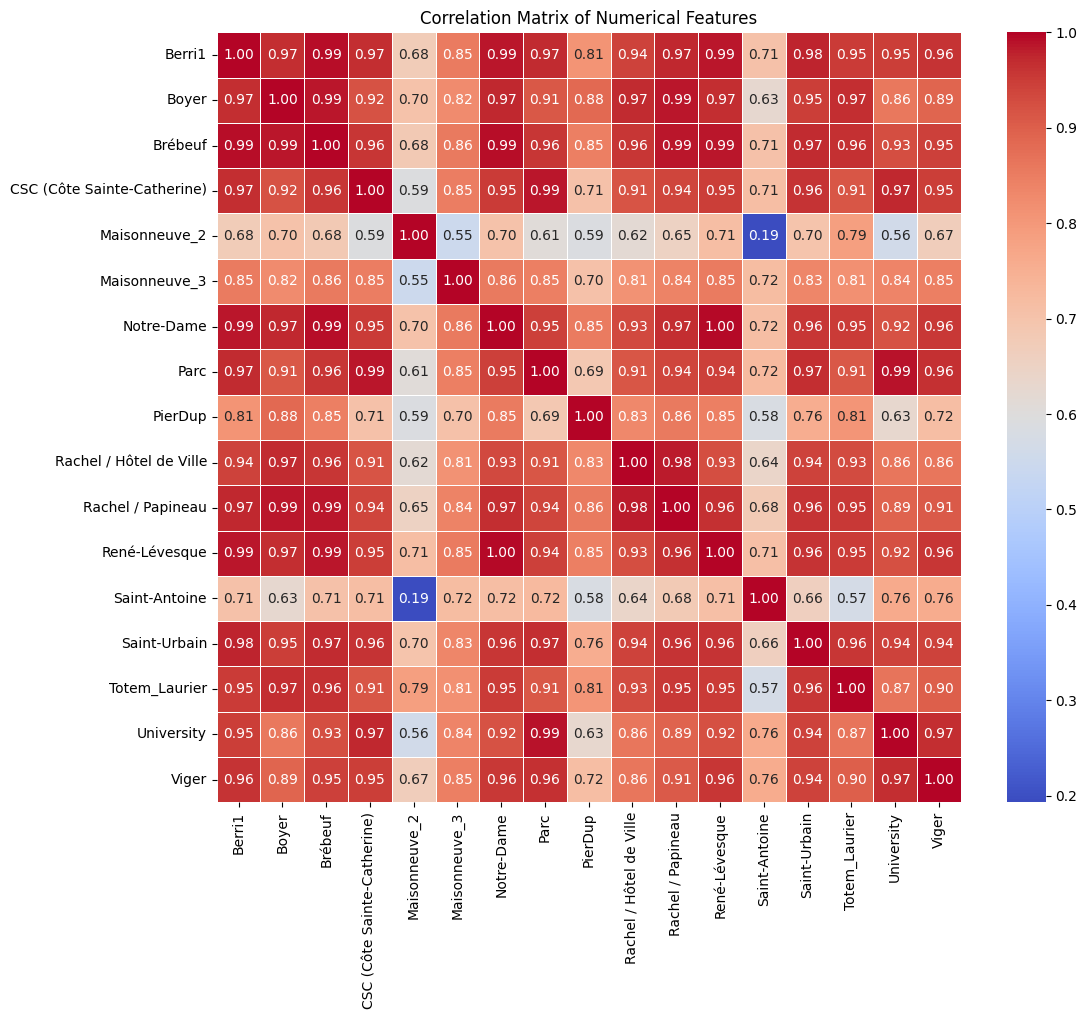

In [61]:
plt.figure(figsize=(12, 10))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

Most streets have collinearity with each other, which is not surprising as they are from the same city.

Fit a GLM with Poisson distribution.

Since we are dealing with a time series data, we will not shuffle the data when performing train test split.

In [49]:
features_to_exclude = ['Date', 'Unnamed: 1', 'Berri1']
X = np.array(df.drop(columns=[col for col in features_to_exclude if col in df.columns]))
y = np.array(df['Berri1'])

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False, test_size=0.2, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (255, 16)
Shape of X_test: (64, 16)
Shape of y_train: (255,)
Shape of y_test: (64,)


In [78]:
def score_estimator(estimator, X_test, y_test):
    y_pred = estimator.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
    print(f"R-squared: {r2:.2f}")
    return mae, rmse, r2

I decided to use RobustScaler to handle outliers. There is no difference compared to StandardScaler

In [85]:
pois_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('poisson_regressor', PoissonRegressor(alpha=1e-12, solver="newton-cholesky"))
])


pois_pipeline.fit(X_train, y_train)

y_pred_pois = pois_pipeline.predict(X_test)

pois_scores = score_estimator(pois_pipeline, X_test, y_test)


Mean Absolute Error (MAE): 651.99
Root Mean Squared Error (RMSE): 763.27
R-squared: 0.78


We compare it with the simple OLS regression

In [79]:
ols_pipeline = Pipeline([
    ('scaler', RobustScaler()),
    ('ols_regressor', LinearRegression())
])


ols_pipeline.fit(X_train, y_train)

y_pred_ols = ols_pipeline.predict(X_test)

ols_scores = score_estimator(ols_pipeline, X_test, y_test)

Mean Absolute Error (MAE): 215.23
Root Mean Squared Error (RMSE): 279.73
R-squared: 0.97


Overall, the Linear regression significantly outperformed the Poisson regression in all metrics. The data contains large ranges of values (0-9999), wsuggesting there are many peaks where the Poisson regression fails to adjust compared to the Linear regression.

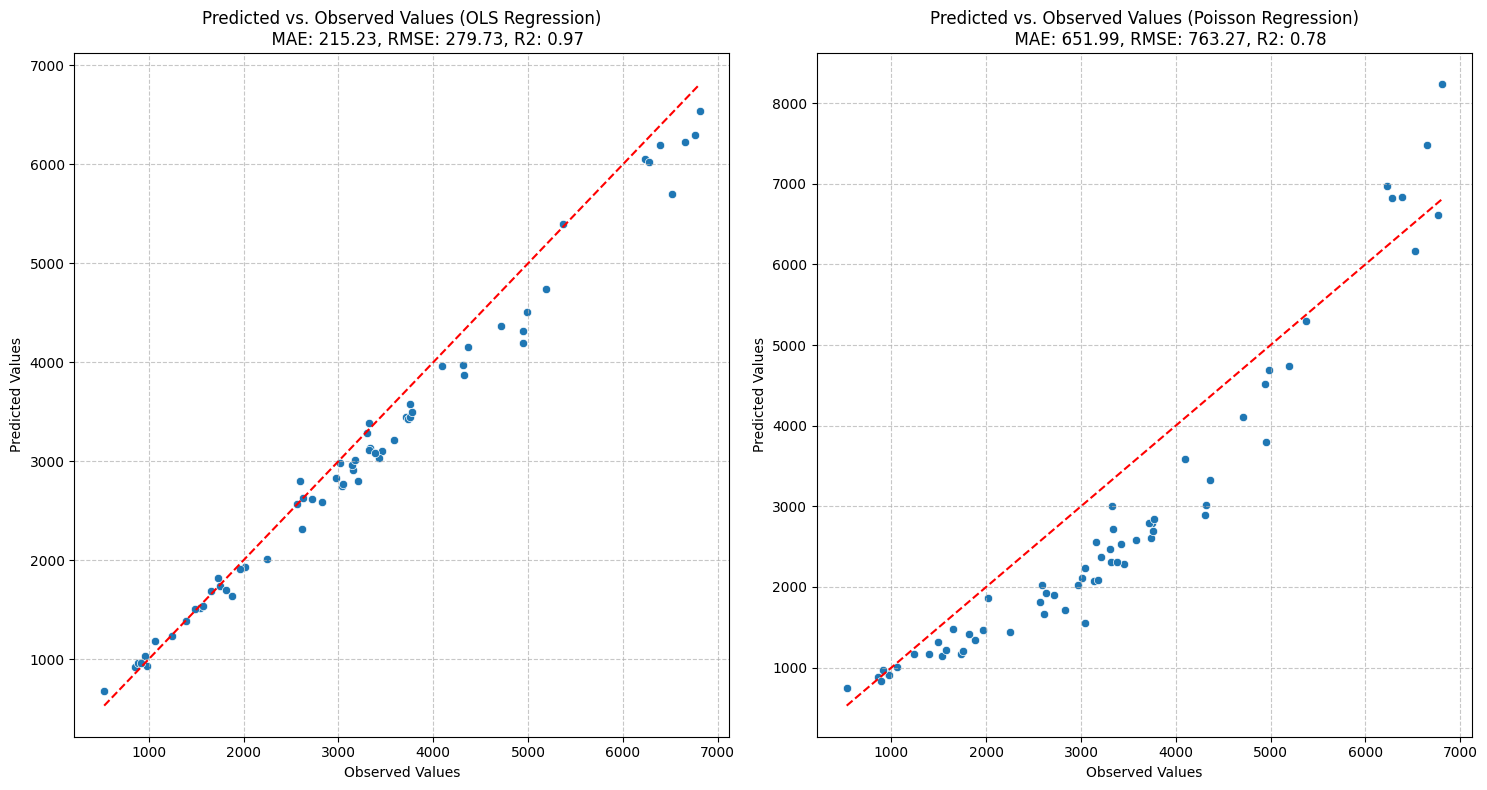

In [116]:
plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred_ols)
plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title(f"""Predicted vs. Observed Values (OLS Regression)
          MAE: {ols_scores[0]:.2f}, RMSE: {ols_scores[1]:.2f}, R2: {ols_scores[2]:.2f}""")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)


plt.subplot(1, 2, 2)
sns.scatterplot(x=y_test, y=y_pred_pois)
plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title(f"""Predicted vs. Observed Values (Poisson Regression)
          MAE: {pois_scores[0]:.2f}, RMSE: {pois_scores[1]:.2f}, R2: {pois_scores[2]:.2f}""")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)


plt.tight_layout()


As can be seen the OLS predictions have a better fit to the straight line compared to the Poisson ones